# The 0.88 s ripple in the AZA_001 MS data, and what a filter does to it

The raw MS mole fractions of AZA_001 (capillary, upstream, total system; sampled every 0.284 s) carry a periodic
oscillation at 0.87–0.89 s (1.13–1.14 Hz), proportional to the signal level. It is the source of the 0.88 s comb in
the CCA_005 kernels (CCA_005_overview, discussion 2026-11-02). This notebook only looks at the data; nothing is fitted.

Filters compared, applied to the raw samples of every species, zero-phase (`scipy.signal.sosfiltfilt`). The raw
time axis is uniform (0.283–0.290 s), so it is filtered as sampled at 0.284 s, split at gaps > 1 s (one gap of 3.8 s,
total system at 2713 s, before its first window). Resampling to an exact grid first is not done: a first version of
this notebook showed that linear resampling alone low-passes near the 1.76 Hz Nyquist frequency (≈ 25 % of the
ripple and up to 2–4 % of F at the capillary fronts).

| variant | what |
|---|---|
| raw | the `.npz` as the CCA scripts read it |
| band-stop | Butterworth band-stops 1.09–1.19 Hz (0.84–0.92 s, the ripple) and 1.22–1.32 Hz (0.76–0.82 s, its second harmonic folded at the Nyquist frequency), order 2 each (4 with filtfilt) |
| low-pass | Butterworth low-pass 0.667 Hz (1.5 s), order 4 (8 with filtfilt) |

Every variant then goes through the CCA_005 windowing (`data_module`: Alex's valve times, 1.0 s before the step, rows
as deviation from the level before the step), so the comparison is on the data as the fits see them.

In [1]:
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.signal as sg

REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == "CCA" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "Experiments" / "CCA"))
import CCA_005 as C  # the data modules exactly as the fits use them

get_ipython().run_line_magic("matplotlib", "inline")  # CCA_005 switches matplotlib to Agg on import
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
SECTIONS = ("cap", "upstream", "total")
SPECIES = ("Ar", "He", "H2")
BAND = (1.09, 1.19)  # Hz, band-stop: the ripple
HARMONIC = (1.22, 1.32)  # Hz, band-stop: its second harmonic folded at the Nyquist frequency
LOWPASS = 1 / 1.5  # Hz
RIPPLE = (1 / 0.97, 1 / 0.80)  # Hz, band in which the ripple is measured

raw = {}
for s in SECTIONS:
    with np.load(C.FILES[s]) as d:
        raw[s] = {"t": d["time_delta"].copy(), "n": d["n_dot"].copy()}
    dt = np.diff(raw[s]["t"])
    print(f"{s:8s}: {raw[s]['t'].size} samples over {raw[s]['t'][-1]:.0f} s, dt median {np.median(dt):.4f} s, "
          f"max {dt.max():.2f} s at t = {raw[s]['t'][np.argmax(dt)]:.0f} s")

DT_RAW = 0.284
FS = 1 / DT_RAW
SOS = {"band-stop": np.vstack([sg.butter(2, BAND, btype="bandstop", fs=FS, output="sos"),
                               sg.butter(2, HARMONIC, btype="bandstop", fs=FS, output="sos")]),
       "low-pass": sg.butter(4, LOWPASS, btype="lowpass", fs=FS, output="sos")}

def apply(sos, t, n):
    # zero-phase filter on the raw samples, segment by segment (split at gaps > 1 s)
    cuts = np.r_[0, np.flatnonzero(np.diff(t) > 1.0) + 1, t.size]
    return np.concatenate([sg.sosfiltfilt(sos, n[..., a:b], axis=-1) for a, b in zip(cuts[:-1], cuts[1:])], axis=-1)

variants = {"raw": {s: (raw[s]["t"], raw[s]["n"]) for s in SECTIONS}}
for v, sos in SOS.items():
    variants[v] = {s: (raw[s]["t"], apply(sos, raw[s]["t"], raw[s]["n"])) for s in SECTIONS}
VARIANTS = tuple(variants)

cap     : 13664 samples over 3874 s, dt median 0.2840 s, max 0.29 s at t = 2053 s
upstream: 44589 samples over 12643 s, dt median 0.2840 s, max 0.29 s at t = 3782 s
total   : 73403 samples over 20817 s, dt median 0.2840 s, max 3.79 s at t = 2713 s


## 1. Frequency response of the filters

Gain of the zero-phase filters (squared Butterworth magnitude), with the ripple band and its folded second harmonic
(2 × 1.13–1.14 Hz = 2.26–2.28 Hz, aliased at the 1.76 Hz Nyquist frequency to 1.24–1.26 Hz).

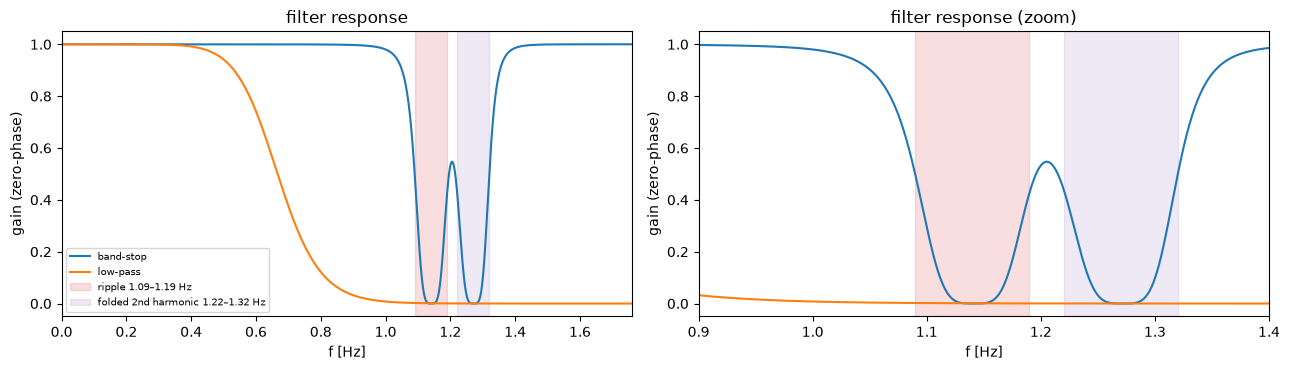

In [2]:
f = np.linspace(0.005, FS / 2, 4000)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for v, sos in SOS.items():
    _, h = sg.sosfreqz(sos, worN=f, fs=FS)
    for a in ax:
        a.plot(f, np.abs(h) ** 2, label=v)
for a, xl in zip(ax, ((0, FS / 2), (0.9, 1.4))):
    a.axvspan(*BAND, color="C3", alpha=0.15, label="ripple 1.09–1.19 Hz")
    a.axvspan(*HARMONIC, color="C4", alpha=0.15, label="folded 2nd harmonic 1.22–1.32 Hz")
    a.set(xlim=xl, xlabel="f [Hz]", ylabel="gain (zero-phase)", title="filter response" + (" (zoom)" if xl[0] else ""))
ax[0].legend(fontsize=7)
fig.tight_layout()

## 2. Spectra before and after

Welch spectra of the relative signal x / trend − 1 (trend: 20 s low-pass), so that the multiplicative ripple is
comparable between species and levels; shaded: the two stop bands. He and H2 are at high levels all the time; Ar is near 0 in half the windows,
so its relative spectrum is noisier.

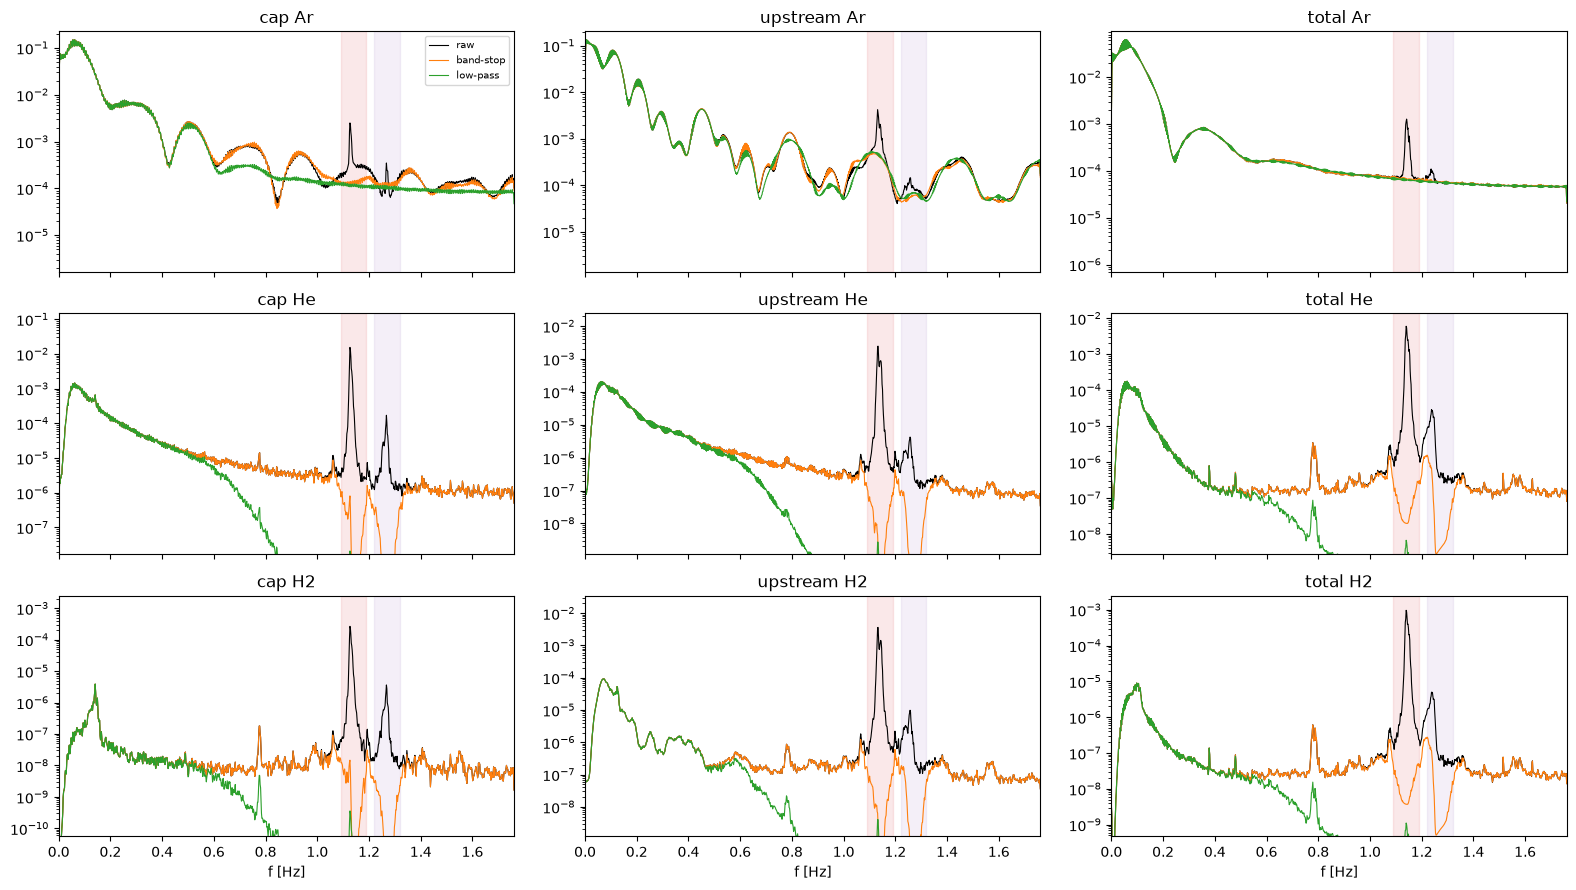

In [3]:
def rel_spectrum(t, x):
    trend = sg.sosfiltfilt(sg.butter(2, 0.05, fs=FS, output="sos"), x)
    ok = np.abs(trend) > 2e-3
    rel = np.where(ok, x / np.where(ok, trend, 1) - 1, 0.0)
    return sg.welch(rel, fs=FS, nperseg=2048)

fig, ax = plt.subplots(len(SPECIES), len(SECTIONS), figsize=(16, 9), sharex=True)
peaks = []
for j, s in enumerate(SECTIONS):
    for i, sp in enumerate(SPECIES):
        lo = None
        for v in ("raw", "band-stop", "low-pass"):
            t, n = variants[v][s]
            fr, P = rel_spectrum(t, n[i])
            ax[i, j].semilogy(fr, P, lw=0.8, label=v, c={"raw": "k", "band-stop": "C1", "low-pass": "C2"}[v])
            band = (fr > RIPPLE[0]) & (fr < RIPPLE[1])
            if v == "raw":
                lo = P[fr > 0.2].min() / 30
                k = np.flatnonzero(band)[np.argmax(P[band])]
                bg = np.median(P[(fr > 0.3) & ~band])
                peaks.append({"section": s, "species": sp, "peak f [Hz]": fr[k], "peak period [s]": 1 / fr[k], "peak / background": P[k] / bg})
        ax[i, j].axvspan(*BAND, color="C3", alpha=0.1)
        ax[i, j].axvspan(*HARMONIC, color="C4", alpha=0.1)
        ax[i, j].set(title=f"{s} {sp}", xlim=(0, FS / 2), ylim=(lo, None))
    ax[-1, j].set_xlabel("f [Hz]")
ax[0, 0].legend(fontsize=7)
fig.tight_layout()
pd.DataFrame(peaks).pivot_table(index="species", columns="section", values=["peak period [s]", "peak / background"], sort=False).style.format(precision=3)

## 3. Raw signal: a plateau and a front

He (high level, small step: where the ripple matters most) and Ar, raw samples (dots) and the filtered signals. Top:
20 s of a plateau; bottom: the front of the same window (step at the valve time + section delay).

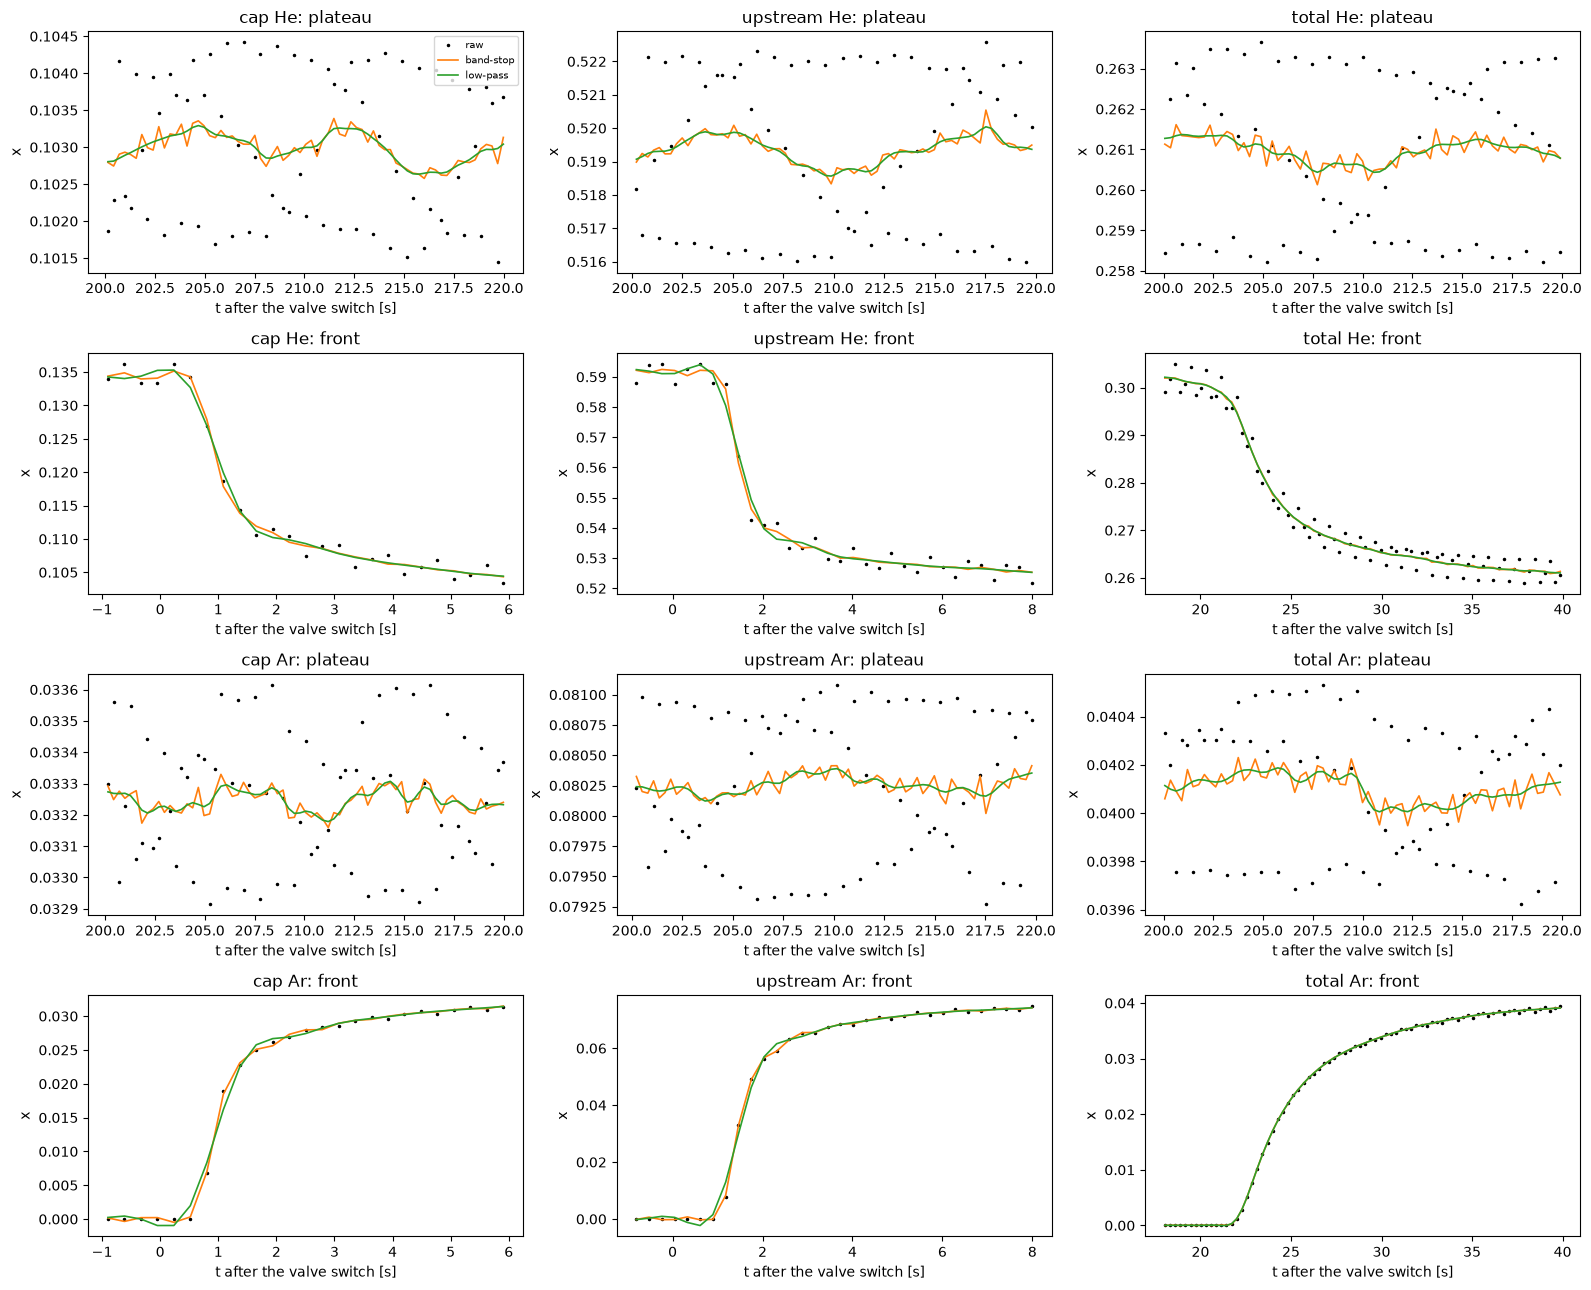

In [4]:
def window_start(s, i):
    return C.ALEX_STARTS[s][i] + C.ALEX_STEP[s]  # valve switch of window i (step position in the CCA windows)

FRONT = {"cap": (-1, 6), "upstream": (-1, 8), "total": (18, 40)}  # s after the switch
fig, ax = plt.subplots(4, 3, figsize=(16, 13))
for j, s in enumerate(SECTIONS):
    t0 = window_start(s, 2)
    for r, (sp, k) in enumerate((("He", 1), ("Ar", 0))):
        for row, (lo, hi) in ((2 * r, (t0 + 200, t0 + 220)), (2 * r + 1, (t0 + FRONT[s][0], t0 + FRONT[s][1]))):
            a = ax[row, j]
            t, n = variants["raw"][s]
            m = (t >= lo) & (t <= hi)
            a.plot(t[m] - t0, n[k, m], "k.", ms=3, label="raw")
            for v, c in (("band-stop", "C1"), ("low-pass", "C2")):
                tv, nv = variants[v][s]
                mv = (tv >= lo) & (tv <= hi)
                a.plot(tv[mv] - t0, nv[k, mv], c=c, lw=1.2, label=v)
            a.set(title=f"{s} {sp}: " + ("plateau" if row % 2 == 0 else "front"), xlabel="t after the valve switch [s]", ylabel="x")
ax[0, 0].legend(fontsize=7)
fig.tight_layout()

## 4. Front distortion on noise-free fronts

What a filter does to a front without any ripple or noise: model fronts F(t) (unit step responses of the CCA_003
Ar+He kernels: capillary E_cap, upstream E_up ⊗ E_cap, total E_up ⊗ E_down ⊗ E_cap), sampled at the real raw time
stamps around every valve switch of the section (so with the real sampling phases), filtered or not, then
interpolated onto the window grid as the data modules do. Difference filtered − unfiltered: mean over the windows
(line) and range (band); crossing-time shifts by linear interpolation between grid points.

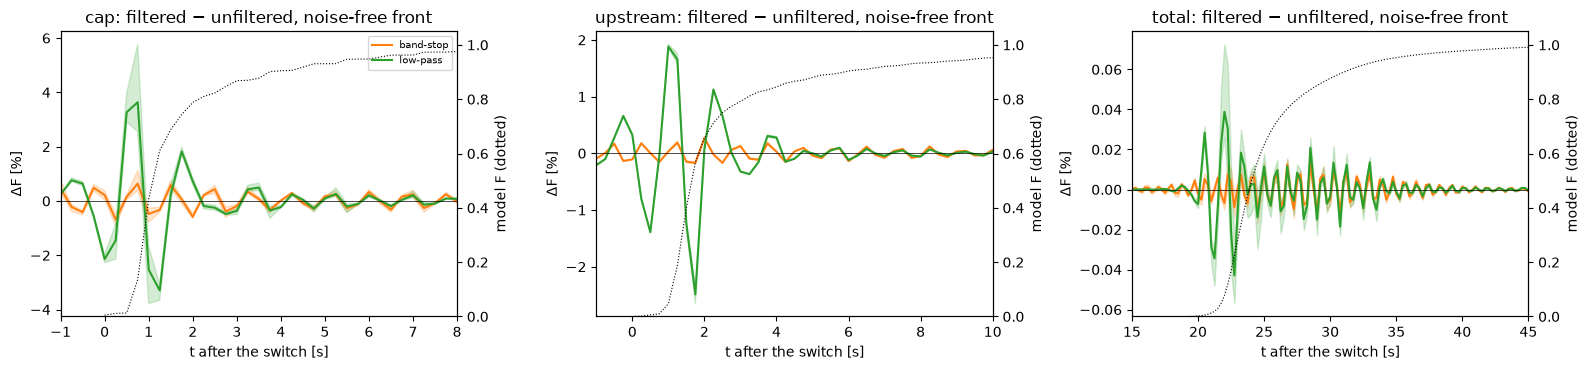

In [5]:
run = np.load(sorted(p for p in (REPO / "Experiments/CCA/Runs").glob("CCA_003_ArHe_*.npy") if len(p.stem) == len("CCA_003_ArHe_2026-10-31_135759"))[-1], allow_pickle=True).item()
E_up, E_down, E_cap = (np.asarray(e) for e in run["Es"])
DTK = 0.25
chain = {"cap": E_cap, "upstream": np.convolve(E_up, E_cap) * DTK, "total": np.convolve(np.convolve(E_up, E_down) * DTK, E_cap) * DTK}
t_model = {s: np.arange(chain[s].size) * DTK for s in SECTIONS}
F_model = {s: np.cumsum(chain[s]) * DTK for s in SECTIONS}

def crossing(t, F, level):
    i = np.argmax(F > level)
    return t[i - 1] + (level - F[i - 1]) / (F[i] - F[i - 1]) * (t[i] - t[i - 1])

t_win = np.linspace(*C.T_OUT, C.N_OUT) - C.SWITCH_DELAY  # window grid, relative to the switch
dist, rows = {}, []
for s in SECTIONS:
    t_raw = raw[s]["t"]
    for v, sos in SOS.items():
        dF, shifts = [], []
        for i in range(len(C.ALEX_STARTS[s]) - 1):
            t_sw = C.ALEX_STARTS[s][i] + C.ALEX_STEP[s]
            m = (t_raw > t_sw - 150) & (t_raw < t_sw + 150)
            tr = t_raw[m] - t_sw
            x = np.interp(tr, t_model[s], F_model[s], left=0.0, right=F_model[s][-1])
            y0 = np.interp(t_win, tr, x)
            y1 = np.interp(t_win, tr, apply(sos, tr, x))
            dF.append(y1 - y0)
            shifts.append([crossing(t_win, y1, l) - crossing(t_win, y0, l) for l in (0.1, 0.5, 0.9)])
        dF, shifts = np.array(dF), np.array(shifts)
        dist[s, v] = dF
        rows.append({"section": s, "filter": v, "max |ΔF| [%]": 100 * np.abs(dF).max(), "RMS ΔF [%]": 100 * np.sqrt(np.mean(dF**2)),
                     **{f"Δt{k} [s]": shifts[:, j].mean() for j, k in enumerate((10, 50, 90))}})

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
XL = {"cap": (-1, 8), "upstream": (-1, 10), "total": (15, 45)}
for j, s in enumerate(SECTIONS):
    for v, c in (("band-stop", "C1"), ("low-pass", "C2")):
        d = 100 * dist[s, v]
        ax[j].fill_between(t_win, d.min(0), d.max(0), color=c, alpha=0.2)
        ax[j].plot(t_win, d.mean(0), c=c, label=v)
    ax2 = ax[j].twinx()
    ax2.plot(t_model[s], F_model[s], c="k", lw=0.8, ls=":")
    ax2.set(ylim=(0, 1.05), ylabel="model F (dotted)")
    ax[j].axhline(0, c="k", lw=0.5)
    ax[j].set(xlim=XL[s], title=f"{s}: filtered − unfiltered, noise-free front", xlabel="t after the switch [s]", ylabel="ΔF [%]")
ax[0].legend(fontsize=7)
fig.tight_layout()
pd.DataFrame(rows).set_index(["section", "filter"]).style.format("{:.3f}")

## 5. The data as the fits see them

Every variant through the CCA_005 windowing (all rows of Ar and He). Per section and group, on the plateau after the
front: the ripple (0.80–0.97 s band) per row and in the mean of the rows, and the scatter between the rows (the
"repeat std" of the overviews); the t50 shift of the mean F (t10/t90 of the He groups move with the ripple itself,
so they are not a distortion measure here).

In [6]:
GROUPS = {"Ar rise": ("Ar", "BU"), "Ar fall": ("Ar", "BT"), "He rise": ("He", "BT"), "He fall": ("He", "BU")}
C.TRACERS = "Ar+He"
tmp = Path(tempfile.mkdtemp())
win = {}  # (variant, section) -> data module
for v in VARIANTS:
    for s in SECTIONS:
        t, n = variants[v][s]
        path = tmp / f"{v}_{s}.npz"
        np.savez(path, n_dot=n, time_delta=t)
        C.FILES[s] = path
        win[v, s] = C.data_module(s)

def F_of(dm):
    x = dm.x[:, 0].numpy(); y = dm.y[:, 0].numpy()
    return (y - x[:, :1]) / (x[:, -1:] - x[:, :1])

def rows_of(dm, g):
    tr, d = GROUPS[g]
    return np.flatnonzero((dm.tracer == tr) & (dm.direction == d))

def band_rms(w, dt=0.25):
    W = np.fft.rfft(w - w.mean()); f = np.fft.rfftfreq(w.size, dt)
    W[~((f > RIPPLE[0]) & (f < RIPPLE[1]))] = 0
    return np.sqrt(np.mean(np.fft.irfft(W, w.size) ** 2))

PLATEAU = {"cap": (15, 45), "upstream": (15, 60), "total": (45, 115)}  # s in the window, after the front
meanF = {}
rows = []
for s in SECTIONS:
    t = win["raw", s].t_out[0].numpy()
    pl = (t >= PLATEAU[s][0]) & (t <= PLATEAU[s][1])
    for g in GROUPS:
        for v in VARIANTS:
            Fv = F_of(win[v, s])[rows_of(win[v, s], g)]
            meanF[v, s, g] = Fv.mean(axis=0)
            rows.append({"section": s, "group": g, "variant": v,
                         "ripple per row [% of Δ]": 100 * np.mean([band_rms(w[pl]) for w in Fv]),
                         "ripple in mean [% of Δ]": 100 * band_rms(meanF[v, s, g][pl]),
                         "scatter between rows [% of Δ]": 100 * Fv[:, pl].std(axis=0).mean(),
                         "Δt50 of the mean [s]": crossing(t, meanF[v, s, g], 0.5) - crossing(t, meanF["raw", s, g], 0.5)})
effect = pd.DataFrame(rows)
effect.set_index(["section", "group", "variant"]).style.format("{:.3f}")

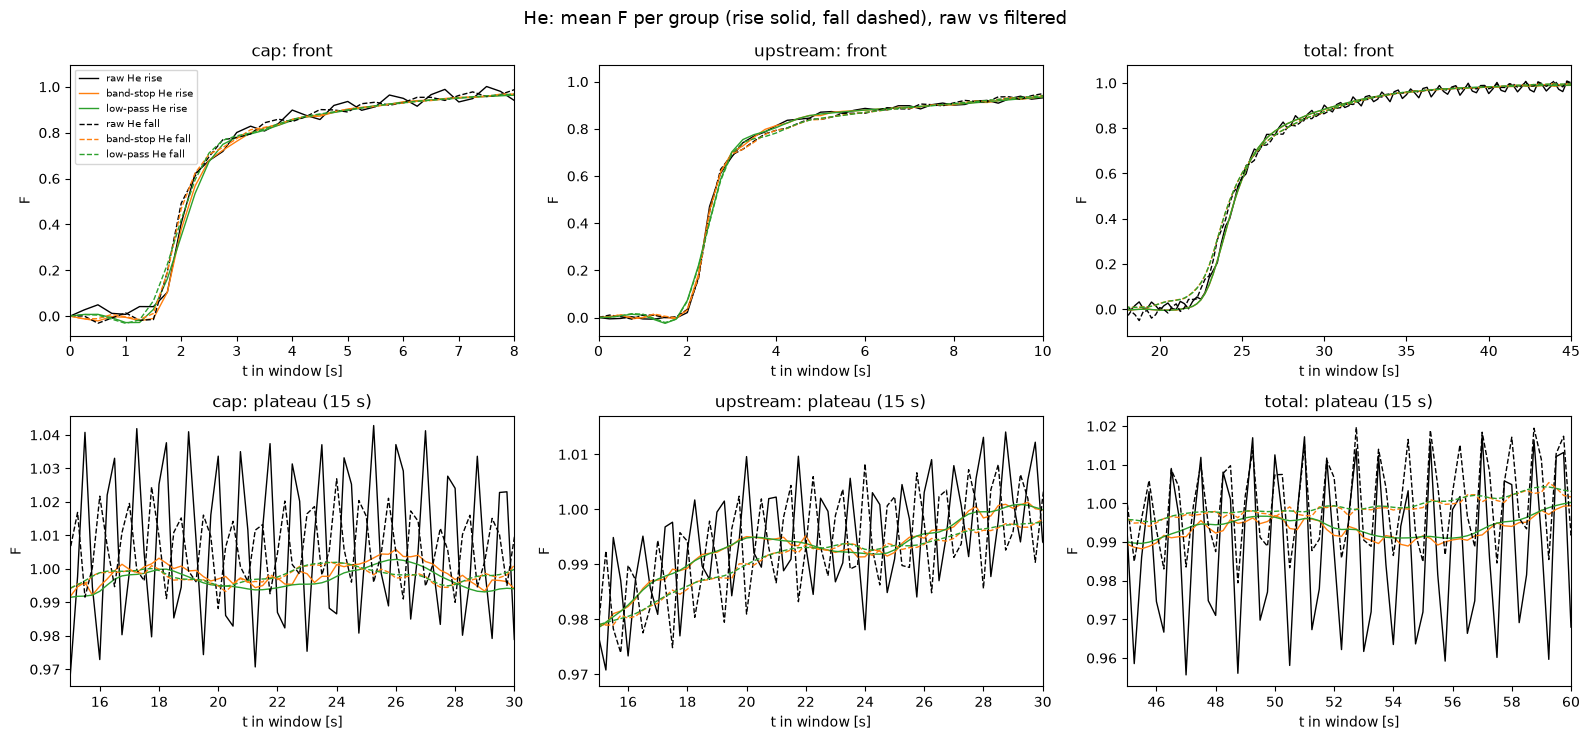

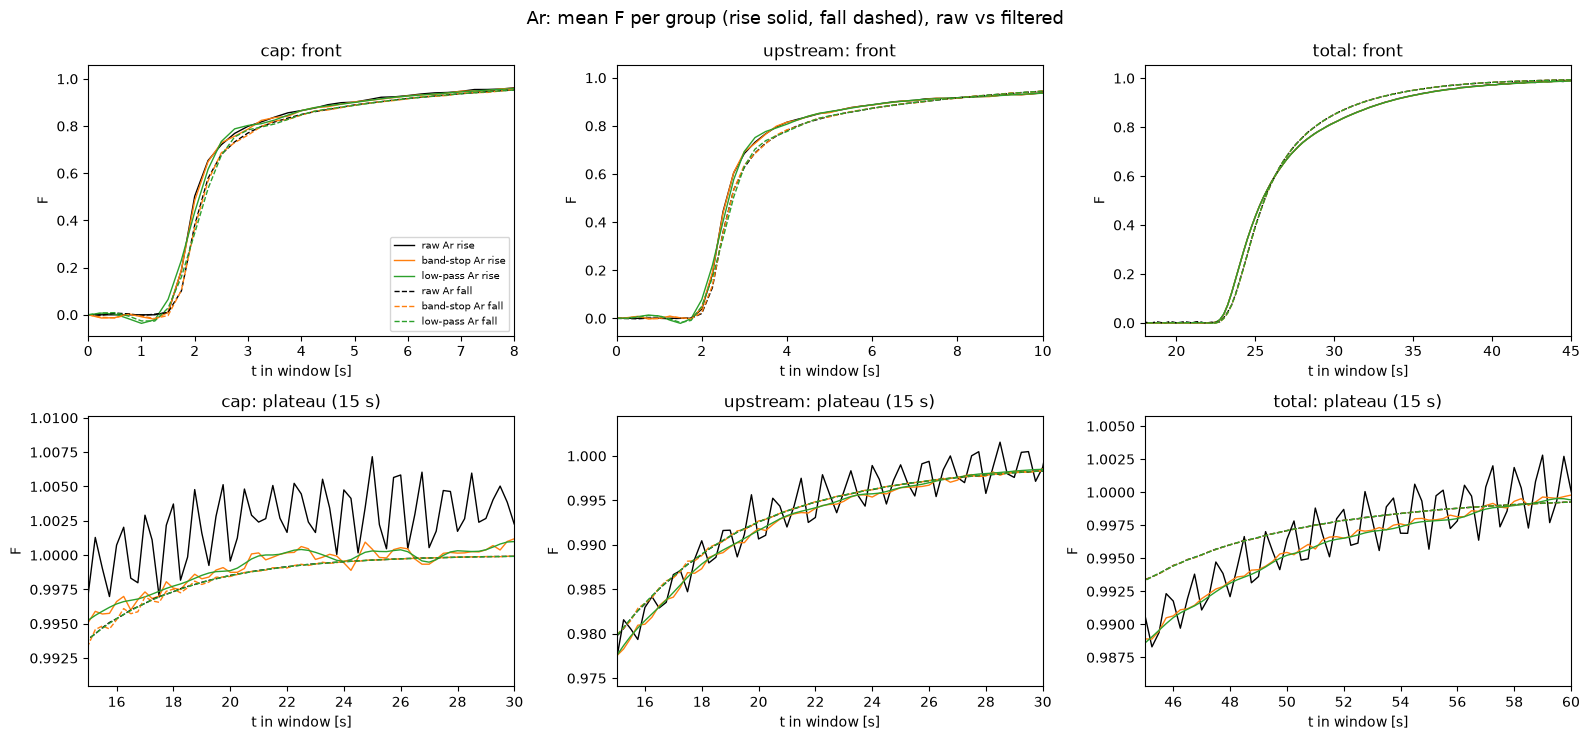

In [7]:
XL = {"cap": (0, 8), "upstream": (0, 10), "total": (18, 45)}
VCOL = {"raw": "k", "band-stop": "C1", "low-pass": "C2"}
for g_pair in (("He rise", "He fall"), ("Ar rise", "Ar fall")):
    fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
    fig.suptitle(f"{g_pair[0][:2]}: mean F per group (rise solid, fall dashed), raw vs filtered", fontsize=13)
    for j, s in enumerate(SECTIONS):
        t = win["raw", s].t_out[0].numpy()
        for g, ls in zip(g_pair, ("-", "--")):
            for v in VARIANTS:
                ax[0, j].plot(t, meanF[v, s, g], c=VCOL[v], ls=ls, lw=1, label=f"{v} {g}")
                ax[1, j].plot(t, meanF[v, s, g], c=VCOL[v], ls=ls, lw=1)
        ax[0, j].set(xlim=XL[s], title=f"{s}: front", xlabel="t in window [s]", ylabel="F")
        lo, hi = PLATEAU[s]
        sel = (t >= lo) & (t <= lo + 15)
        ys = np.concatenate([meanF[v, s, g][sel] for g in g_pair for v in VARIANTS])
        ax[1, j].set(xlim=(lo, lo + 15), ylim=(ys.min() - 0.003, ys.max() + 0.003), title=f"{s}: plateau (15 s)", xlabel="t in window [s]", ylabel="F")
    ax[0, 0].legend(fontsize=7)
    fig.tight_layout()

## 6. Findings (facts from the tables above, state 2026-11-02)

**The ripple.** Period 0.888 s (capillary), 0.883 s (upstream), 0.877 s (total system): one narrow line per
measurement whose frequency differs slightly between the files, 4 000–34 000× above the spectral background for He
and H2 (section 2; Ar is near 0 in half the windows, so its relative spectrum is noisier). Its second harmonic folds
back at the 1.76 Hz Nyquist frequency to ≈ 1.26 Hz. A weaker line at ≈ 0.78 Hz (1.28 s) in He and H2 is left by both
stop bands. Per row the ripple is 0.4–0.5 % of the step for Ar rises and 2.2–3.9 % for He (section 5); it is
proportional to the level, so Ar falls (level ≈ 0 after the step) carry none.

**Band-stop (1.09–1.19 Hz and 1.22–1.32 Hz).**
- Removes 95–97 % of the ripple per row (He capillary 3.06 → 0.10 % of Δ, upstream 2.69 → 0.08 %, total 3.86 → 0.16 %;
  Ar rises 0.43–0.54 → 0.02–0.05 %); in the mean of the rows ≤ 0.06 % of Δ is left.
- Front distortion on noise-free model fronts (section 4): max |ΔF| 1.1 % at the capillary front, 0.28 % upstream,
  0.02 % in the total system; crossing times shift by ≤ 0.008 s (t10, t50) and 0.06 s (t90, capillary). The residue is
  a ringing at the stop-band frequency right at the steep capillary front, decaying within ≈ 5 s.
- t50 of the measured mean F shifts by ≤ 0.05 s.

**Low-pass (1.5 s).**
- Removes the ripple slightly further (≤ 0.04 % of Δ left per row) but distorts the fronts: max |ΔF| 5.8 % in the
  capillary, 2.7 % upstream (0.07 % total); t10 −0.06 s, t50 +0.04 s at the capillary. It also removes real front
  content: the 0.4–1 Hz structure of the capillary Ar spectrum (section 2) is gone.
- The scatter between rows is the same as with the band-stop (e.g. He upstream 1.19 vs 1.20 % of Δ): beyond the ripple,
  the remaining scatter sits at periods longer than 1.5 s, where neither filter acts.

**What the ripple was in the scatter.** Most of the between-row scatter outside the capillary: He upstream 2.9 → 1.2 %
of Δ, total 3.9 → 1.3 %; Ar rises upstream 0.61 → 0.31 %, total 0.54 → 0.30 %. In the capillary less (He 3.6 → 2.8 %,
Ar rises 0.99 → 0.92 %): there the other noise dominates.

**Not checked here:** what the ripple's source is (it scales with the level of every species, so a common
multiplicative factor, e.g. pressure or inlet flow at the MS, would fit); whether its phase is tied to the valve
switching (CCA_005 discussion: mostly random upstream, partly locked in the total system); the effect on fitted
kernels (needs a fit, e.g. CCA_006 on band-stopped data).